## Kütüphaneler Veri Yükleme ve Ön işlemlerin Tekrarı

In [151]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels as sm
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error
import matplotlib.dates as mdates

df = pd.read_csv('OnlineRetail.csv', encoding='ISO-8859-1', dtype={'CustomerID': str})
df= df.dropna(subset=['CustomerID'])
silinecekunitprice = df[df["UnitPrice"] <= 0].index
df=df.drop(silinecekunitprice)
df["TotalPrice"] = df["UnitPrice"] * df["Quantity"]
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")
df['Year']=df['InvoiceDate'].dt.year
df['Month']=df['InvoiceDate'].dt.month.astype('Int64')
df['day']=df['InvoiceDate'].dt.day
df['DayOfWeek']=df['InvoiceDate'].dt.day_name()
df['Hour']=df['InvoiceDate'].dt.hour.astype('Int64')

# 5.Talep Tahmini (Zaman Serisi)

### 5.1 Günlük / Haftalık Satış Serisi

In [152]:
daily_sales = df.groupby('InvoiceDate')['TotalPrice'].sum().resample('D').sum()

In [153]:
split_idx = int(len(daily_sales) * 0.8)

train = daily_sales.iloc[:split_idx]
test = daily_sales.iloc[split_idx:]

print(f"Eğitim gün sayısı: {len(train)}, Test gün sayısı: {len(test)}")

Eğitim gün sayısı: 558, Test gün sayısı: 140


### 5.2 Model Seçimi

In [154]:
model = ExponentialSmoothing(train,trend="add",
    seasonal="add",  #çarpımsalda yapabilirdik ama yönlendirme dosyasında belirtilmemiş bende kolay olan toplamsalı seçtim :)
    seasonal_periods=7,damped_trend=True)
fit_model = model.fit()
predictions = fit_model.forecast(steps=len(test))
predictions.head()

2011-07-24    1800.388652
2011-07-25    -367.554283
2011-07-26    1367.136766
2011-07-27    -530.627869
2011-07-28     930.506877
Freq: D, dtype: float64

### 5.3 Değerlendirme

In [155]:
mae = mean_absolute_error(test, predictions)
rmse = root_mean_squared_error(test, predictions)
mape = mean_absolute_percentage_error(test, predictions)

print(mae)
print(rmse)
print(mape)

9366.598096362724
17204.194386675033
2.6908190494757647e+18


#### Şimdi tabi hatalar devasa çıktı bunun nedeni negatif değerlerin olması muhtemelen toplamsal model yerine birde çarpımsal modelide deneyelim

In [156]:
daily_sales_clean = daily_sales.copy()
daily_sales_clean[daily_sales_clean <= 0] = 1
split_idx = int(len(daily_sales_clean) * 0.8)
train = daily_sales_clean.iloc[:split_idx]
test = daily_sales_clean.iloc[split_idx:]

In [157]:
model = ExponentialSmoothing(train,trend="add",
seasonal="mul",  # Toplamsal kolay demiştik bu sefer seve seve çarpımsal kullanıcaz tabi bu haliyle karma oldu olmazsa tamamen çarpımsalı da kullanırız.
    seasonal_periods=7,damped_trend=True,initialization_method="heuristic")

In [158]:
fit_model = model.fit()
predictions = fit_model.forecast(steps=len(test))

In [159]:
mae = mean_absolute_error(test, predictions)
rmse = root_mean_squared_error(test, predictions)
wape = (np.sum(np.abs(test - predictions)) / np.sum(test)) * 100

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE (%): {wape:.2f}%")

MAE: 10430.11
RMSE: 15700.74
WAPE (%): 116.24%


#### Buda çok yüksek çıktı birde karma yerine tamamen çarpımsal bir model kullanalım

In [160]:
daily_sales_clean = daily_sales.copy()
daily_sales_clean[daily_sales_clean <= 0] = 1
split_idx = int(len(daily_sales_clean) * 0.8)
train = daily_sales_clean.iloc[:split_idx]
test = daily_sales_clean.iloc[split_idx:]

In [161]:
model = ExponentialSmoothing(train,trend="mul",
seasonal="mul",  # Bu sefer tamamen çarpımsal
    seasonal_periods=7,damped_trend=True,initialization_method="heuristic")

In [162]:
fit_model = model.fit()
predictions = fit_model.forecast(steps=len(test))

C:\Users\afay1\PycharmProjects\Portfoy_projeleri\.venv\Lib\site-packages\statsmodels\tsa\holtwinters\model.py:85: RuntimeWarning: overflow encountered in matmul
  return err.T @ err


In [163]:
mae = mean_absolute_error(test, predictions)
rmse = root_mean_squared_error(test, predictions)
wape = (np.sum(np.abs(test - predictions)) / np.sum(test)) * 100

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE (%): {wape:.2f}%")

MAE: 12241.02
RMSE: 15239.48
WAPE (%): 136.43%


#### Rakamlar yine yüksek muhtemelen holt winters yöntemi yetersiz. diğer yöntemleri yani ARIMA & SARIMA modelleri denemek lazım ama 23.11.2026 tarihi itibarı ile Zaman Serisi dersini almaya devam ediyorum ve o konulara geçmediğimiz için şuan pek ona geçmek istemedim. Görselleştirmemizi yapıp çalışmamızı bitirelim.

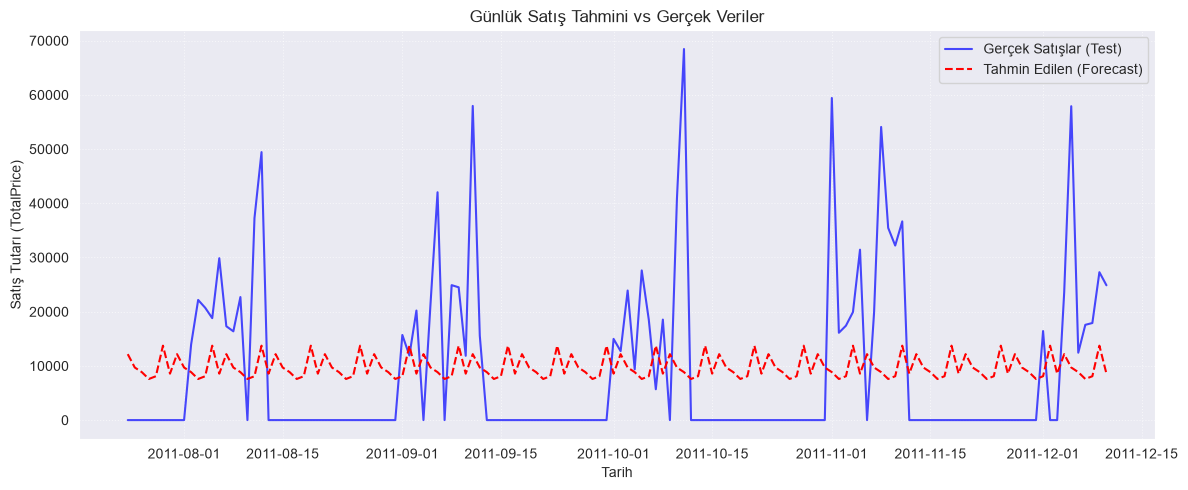

In [165]:
plt.figure(figsize=(12, 5))

plt.plot(test.index, test, label='Gerçek Satışlar (Test)', color='blue', alpha=0.7)
plt.plot(predictions.index, predictions, label='Tahmin Edilen (Forecast)', color='red', linestyle='--')
plt.title('Günlük Satış Tahmini vs Gerçek Veriler')
plt.xlabel('Tarih')
plt.ylabel('Satış Tutarı (TotalPrice)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("forecast_plot.png", bbox_inches='tight', dpi=300)
plt.show()

### Evet tahminin ne kadar gerçek veriden uzak olduğuda burada gözüküyor